# MOPITT CO at 500 hPa — gap filling, mean & SD maps

- **Input:** `Data/MOPITT-cropped-greater-domain/<YYYYMM>.nc` (box subsets from `mopitt.ipynb`)
- **Variable:** `RetrievedCOMixingRatioProfileDay` at the 500 hPa level (ppbv, daytime retrieval)
- **Window:** Jan 2003 – Dec 2023 (252 months; Aug & Sep 2009 do not exist and are interpolated)

In [4]:
# Setup: config + imports
import glob
import os
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

# Config
CROP_OUT_DIR = "../../Data/MOPITT-cropped-greater-domain"
VARNAME      = "RetrievedCOMixingRatioProfileDay"
PRES_LEVEL   = 700.0                   # hPa
OUT_DIR      = "../../Figures/mopitt"
os.makedirs(OUT_DIR, exist_ok=True)

# Balanced window: 21 whole years
START_TS = pd.Timestamp("2003-01-01")
END_TS   = pd.Timestamp("2023-12-01")

## Interpolation to fill gaps in the data (Aug & Sep 2009 + per-pixel gaps)

In [5]:
# Build gap-free monthly 500 hPa maps over the window, then the spatial-mean series.
crop_files = sorted(glob.glob(os.path.join(CROP_OUT_DIR, "*.nc")))
print(f"Found {len(crop_files)} cropped files")

# Load each month's (lat, lon) map at 500 hPa.
obs_maps = {}
lons = lats = None
for f in crop_files:
    stem = os.path.splitext(os.path.basename(f))[0]
    date = pd.Timestamp(f"{stem[:4]}-{stem[4:]}-01")
    if not (START_TS <= date <= END_TS):
        continue
    ds_g = xr.open_dataset(f)
    if lons is None:
        lons = ds_g["lon"].values
        lats = ds_g["lat"].values
        k500 = int(np.where(ds_g["Pressure"].values == PRES_LEVEL)[0][0])
        UNITS = ds_g[VARNAME].attrs.get("units", "ppbv")
        print(f"Pressure levels: {ds_g['Pressure'].values}  ->  using index {k500} ({PRES_LEVEL:.0f} hPa)")
    obs_maps[date] = ds_g[VARNAME].isel(Prs=k500).values
    ds_g.close()

n_lat, n_lon = len(lats), len(lons)

# Full monthly calendar over the window.
months = pd.date_range(START_TS, END_TS, freq="MS")

# Stack into a (time, lat, lon) cube; missing months stay all-NaN.
raw_maps = np.full((len(months), n_lat, n_lon), np.nan)
has_obs = np.zeros(len(months), dtype=bool)
for i, d in enumerate(months):
    if d in obs_maps:
        raw_maps[i] = obs_maps[d]
        has_obs[i] = True
is_interp = ~has_obs

# Interpolate maps in time, per pixel, to fill missing months (and missing pixels).
final_maps = xr.DataArray(
    raw_maps, dims=("time", "lat", "lon"),
    coords={"time": months, "lat": lats, "lon": lons},
)
final_maps = (final_maps.interpolate_na(dim="time", method="linear")
                        .bfill("time").ffill("time"))

# Time series = spatial mean of each map.
ts_dates = months
ts_co    = final_maps.mean(dim=("lat", "lon"), skipna=True).values

# Diagnostics.
n_pix = n_lat * n_lon
filled_dates = [d.strftime('%Y-%m') for d in months[is_interp]]
print(f"Calendar months    : {len(months)}   ({START_TS:%b %Y} - {END_TS:%b %Y})")
print(f"Observed maps      : {has_obs.sum()}")
print(f"Reconstructed maps : {is_interp.sum()}  -> {filled_dates}")
print(f"Grid per map       : {n_lat} lat x {n_lon} lon = {n_pix} pixels")
for i in np.where(is_interp)[0]:
    n_valid_orig = int(np.isfinite(raw_maps[i]).sum())
    n_valid_new  = int(np.isfinite(final_maps.values[i]).sum())
    print(f"   {months[i].strftime('%Y-%m')}: filled {n_valid_new - n_valid_orig} "
          f"pixels  ->  map mean = {ts_co[i]:.2f} {UNITS}")

# Pixel gaps inside observed months (clouds, retrieval failures).
obs_valid = np.isfinite(raw_maps[has_obs])
n_gap = int((~obs_valid).sum())
print(f"Pixel gaps in observed months filled: {n_gap}  "
      f"({n_gap / obs_valid.size:.1%} of observed pixel-months; "
      f"per month {(~obs_valid).mean(axis=(1, 2)).min():.1%} - {(~obs_valid).mean(axis=(1, 2)).max():.1%})")

n_dead = int(np.isnan(final_maps.values).all(axis=0).sum())
print(f"Pixels never observed (left NaN): {n_dead}")
print(f"Date range : {ts_dates[0].date()}  ->  {ts_dates[-1].date()}")
print(f"CO range   : {np.nanmin(ts_co):.2f} - {np.nanmax(ts_co):.2f}  {UNITS}")

Found 250 cropped files
Pressure levels: [900. 800. 700. 600. 500. 400. 300. 200. 100.]  ->  using index 2 (700 hPa)
Calendar months    : 252   (Jan 2003 - Dec 2023)
Observed maps      : 250
Reconstructed maps : 2  -> ['2009-08', '2009-09']
Grid per map       : 69 lat x 124 lon = 8556 pixels
   2009-08: filled 8556 pixels  ->  map mean = 80.94 ppbv
   2009-09: filled 8556 pixels  ->  map mean = 80.24 ppbv
Pixel gaps in observed months filled: 172900  (8.1% of observed pixel-months; per month 0.5% - 52.2%)
Pixels never observed (left NaN): 0
Date range : 2003-01-01  ->  2023-12-01
CO range   : 78.06 - 132.32  ppbv


## Mean and SD maps

Stack shape : (252, 69, 124)   (2003-01 - 2023-12)
Mean range  : 65.53 - 126.06  ppbv
Std  range  : 7.59 - 35.12  ppbv


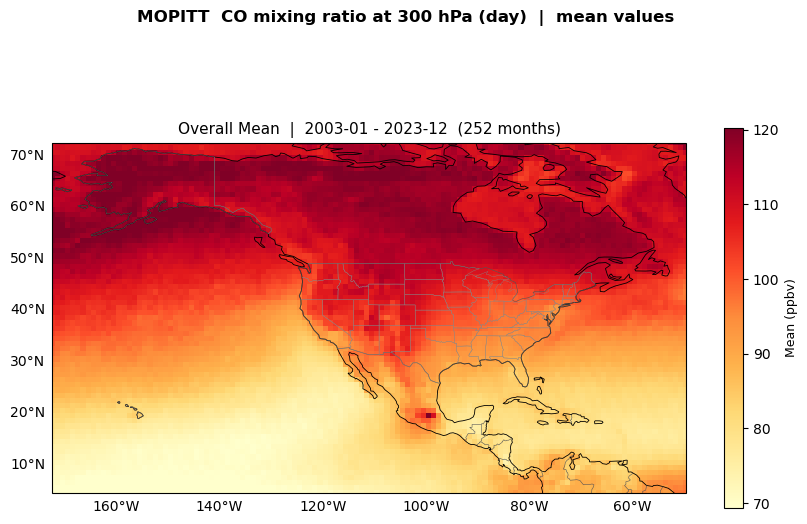

Saved -> ../../Figures/mopitt\co_300hpa_mean_2003_2023.png


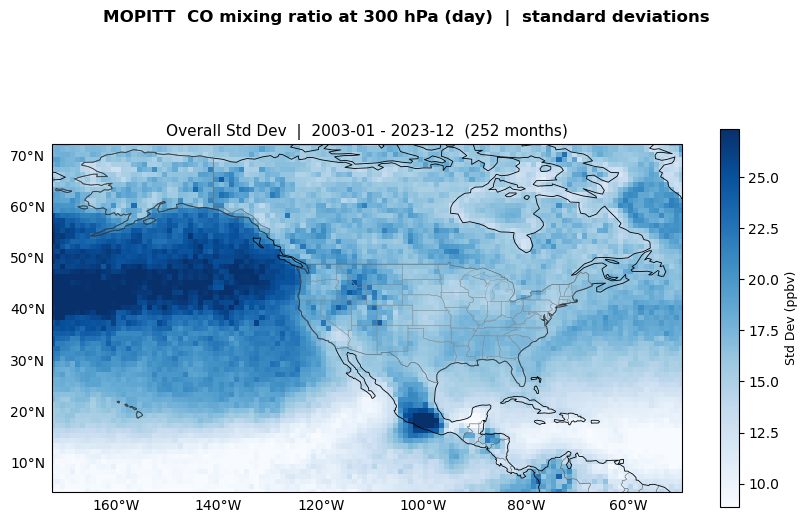

Saved -> ../../Figures/mopitt\co_300hpa_std_2003_2023.png


In [6]:
# Pixel-wise mean & std across all months of the gap-free cube.
import cartopy.crs as ccrs
import cartopy.feature as cfeature

FIG_DIR = OUT_DIR
os.makedirs(FIG_DIR, exist_ok=True)

stack   = final_maps.values
co_mean = np.nanmean(stack, axis=0)
co_std  = np.nanstd (stack, axis=0, ddof=1)

n_months    = stack.shape[0]
label_first = months[0].strftime("%Y-%m")
label_last  = months[-1].strftime("%Y-%m")

print(f"Stack shape : {stack.shape}   ({label_first} - {label_last})")
print(f"Mean range  : {np.nanmin(co_mean):.2f} - {np.nanmax(co_mean):.2f}  {UNITS}")
print(f"Std  range  : {np.nanmin(co_std ):.2f} - {np.nanmax(co_std ):.2f}  {UNITS}")

# Map extent from data coords.
lon_min, lon_max = float(lons.min()), float(lons.max())
lat_min, lat_max = float(lats.min()), float(lats.max())


def draw_map(fig, ax, data, cmap, label, title):
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")

    pcm = ax.pcolormesh(
        lons, lats, data,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        vmin=np.nanpercentile(data, 2), vmax=np.nanpercentile(data, 98),
        shading="nearest",
    )
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False

    cb = fig.colorbar(pcm, ax=ax, orientation="vertical", fraction=0.03, pad=0.06)
    cb.set_label(label, fontsize=9)
    ax.set_title(title, fontsize=11, pad=6)


# Mean map.
fig_mean, ax_mean = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
draw_map(fig_mean, ax_mean, co_mean, plt.cm.YlOrRd,
         f"Mean ({UNITS})",
         f"Overall Mean  |  {label_first} - {label_last}  ({n_months} months)")
fig_mean.suptitle(
    "MOPITT  CO mixing ratio at 300 hPa (day)  |  mean values",
    fontsize=12, fontweight="bold",
)
out_mean = os.path.join(FIG_DIR, "co_300hpa_mean_2003_2023.png")
fig_mean.savefig(out_mean, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_mean)

# Std-dev map.
fig_std, ax_std = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
draw_map(fig_std, ax_std, co_std, plt.cm.Blues,
         f"Std Dev ({UNITS})",
         f"Overall Std Dev  |  {label_first} - {label_last}  ({n_months} months)")
fig_std.suptitle(
    "MOPITT  CO mixing ratio at 300 hPa (day)  |  standard deviations",
    fontsize=12, fontweight="bold",
)
out_std = os.path.join(FIG_DIR, "co_300hpa_std_2003_2023.png")
fig_std.savefig(out_std, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_std)